# TAIX-Transfer · 01 — Data Understanding

**DS 504 | TAIX-Ray bedside chest radiographs | CRISP-DM phase 2**

**Aim:** audit the released cohort, examine ordinal findings and exploratory five-finding definitions, compare train/validation/test populations, and investigate a reproducible **900-image sample** for image geometry, intensity, and decoding quality.

### Contents
1. [Setup and caches](#1-setup-and-caches)
2. [Cohort and official splits](#2-cohort-and-official-splits)
3. [Clinical labels and exploratory findings](#3-clinical-labels-and-exploratory-findings)
4. [Demographics](#4-demographics)
5. [Temporal and longitudinal structure](#5-temporal-and-longitudinal-structure)
6. [Reproducible image sample](#6-reproducible-image-sample)
7. [Image geometry and intensity](#7-image-geometry-and-intensity)
8. [Acquisition-era intensity pattern](#8-acquisition-era-intensity-pattern)
9. [Metadata and image integrity audit](#9-metadata-and-image-integrity-audit)
10. [Conclusions and handoff](#10-conclusions-and-handoff)

> **Evidence scopes:** Metadata analyses use all **215,381** released records; sampled-image results use **300 per split (900 total)**. Neither visual inspection nor numeric label validity constitutes clinical label verification.  
> **Targets not frozen:** the exploratory `grade >= 2` and left/right OR definitions below are **for descriptive EDA only**, not the agreed training-label policy.

**Source:** [TAIX-Ray dataset](https://huggingface.co/datasets/TLAIM/TAIX-Ray) · [Truhn et al., *Scientific Data* (2026)](https://www.nature.com/articles/s41597-026-07271-7).  
See `README_EDA.md` for Colab/local instructions, including sample download costs and storage.

## 1. Setup and caches

**Before Run All:** install dependencies from `requirements-eda.txt` (instructions in `README_EDA.md`). In Colab, the default storage is Google Drive; locally, it is `data/TAIX-Ray` relative to your working directory. Override both using the `TAIX_DATA_DIR` environment variable.

- **Quick rerun:** caches and 900 PNGs already present; no Hugging Face network request needed.
- **First metadata run:** stream the entire Hugging Face metadata once to a Parquet cache.
- **First image run:** set `DOWNLOAD_MISSING_IMAGES = True` to fetch the reproducible sample. This may require streaming through nearly all image rows and can take a long time.
- Caches / images are **not** intended to be committed to GitHub.

In [1]:
# --- Configuration: edit here, rather than changing paths throughout the notebook ---
import os
from pathlib import Path

IN_COLAB = bool(os.getenv("COLAB_RELEASE_TAG")) or "google.colab" in __import__("sys").modules
USE_GOOGLE_DRIVE = IN_COLAB
DOWNLOAD_MISSING_IMAGES = False   # switch to True on first image-sample download
REBUILD_METADATA_CACHE = False    # True only if the cached Parquet needs rebuilding
REBUILD_IMAGE_STATS = False       # recompute the image/pixel CSVs from local PNGs
VERIFY_ALL_SAMPLE_PNGS = False    # True to verify + decode all 900 images (may take minutes)
SAVE_FIGURES = True
SAMPLE_PER_SPLIT = 300
RANDOM_SEED = 0

DATASET_ID = "TLAIM/TAIX-Ray"
DATASET_CONFIG = "default"
DATASET_REVISION = None           # optionally pin a Hugging Face commit hash
SPLITS = ["train", "val", "test"]
EXPECTED_SPLIT_SIZES = {"train": 137593, "val": 34860, "test": 42928}

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

path_default = (
    Path("/content/drive/MyDrive/TAIX-Ray")
    if USE_GOOGLE_DRIVE else Path.cwd() / "data" / "TAIX-Ray"
)
DATA_DIR = Path(os.environ.get("TAIX_DATA_DIR", str(path_default))).expanduser().resolve()
SAMPLE_DIR = DATA_DIR / "eda_image_sample"
OUTPUT_DIR = DATA_DIR / "eda_outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"
METADATA_CACHE = DATA_DIR / "taix_metadata_eda.parquet"
MANIFEST_PATH = DATA_DIR / "eda_image_sample_manifest.csv"
GEOMETRY_CACHE = DATA_DIR / "eda_image_characteristics.csv"
PIXEL_CACHE = DATA_DIR / "eda_pixel_characteristics.csv"

for directory in (DATA_DIR, SAMPLE_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Working dataset directory:", DATA_DIR)
print("Metadata cached:", METADATA_CACHE.exists())
print("Image manifest cached:", MANIFEST_PATH.exists())

Mounted at /content/drive
Working dataset directory: /content/drive/MyDrive/TAIX-Ray
Metadata cached: True
Image manifest cached: True


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from IPython.display import display
from tqdm.auto import tqdm

# Package and environment versions help teammates reproduce the execution environment.
import sys, PIL, datasets
print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Pillow:", PIL.__version__, "| datasets:", datasets.__version__)

plt.rcParams.update({"figure.dpi": 105, "axes.grid": False})

def present(fig, filename):
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

# Optional token. Public downloads may not require authentication.
# Set HF_TOKEN as a local environment variable or a Colab secret (never paste it into notebook code).
HF_TOKEN = os.getenv("HF_TOKEN")
if IN_COLAB and not HF_TOKEN:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

def open_taix_stream():
    """Connect only when caches are missing or an image download was requested."""
    from datasets import load_dataset
    kwargs = {"name": DATASET_CONFIG, "streaming": True}
    if DATASET_REVISION:
        kwargs["revision"] = DATASET_REVISION
    if HF_TOKEN:
        kwargs["token"] = HF_TOKEN
    return load_dataset(DATASET_ID, **kwargs)

Python: 3.13.16
NumPy: 2.1.3 | pandas: 2.2.3
Pillow: 11.3.0 | datasets: 4.8.5


### 1.1 Load or build the **raw** metadata cache

The Parquet file holds only the **16 original dataset columns** (not the derived status/positive columns). Rebuilding streams each split **without including the `Image` column**, so it does not require storing the full image release. Subsequent runs use the Parquet cache.

In [3]:
RAW_COLS = [
    "UID", "Fold", "Split", "PatientID", "PhysicianID", "StudyDate", "Age", "Sex",
    "HeartSize", "PulmonaryCongestion", "PleuralEffusion_Right", "PleuralEffusion_Left",
    "PulmonaryOpacities_Right", "PulmonaryOpacities_Left",
    "Atelectasis_Right", "Atelectasis_Left",
]
LABEL_COLS = RAW_COLS[8:]
BILATERAL = {
    "PleuralEffusion": ("PleuralEffusion_Left", "PleuralEffusion_Right"),
    "PulmonaryOpacities": ("PulmonaryOpacities_Left", "PulmonaryOpacities_Right"),
    "Atelectasis": ("Atelectasis_Left", "Atelectasis_Right"),
}
FINDINGS = ["Cardiomegaly", "Congestion", "PleuralEffusion", "PulmonaryOpacity", "Atelectasis"]

if METADATA_CACHE.exists() and not REBUILD_METADATA_CACHE:
    print("Using cached metadata:", METADATA_CACHE)
    raw_df = pd.read_parquet(METADATA_CACHE)
else:
    print("Streaming raw metadata from Hugging Face; first run may take time...")
    dataset_stream = open_taix_stream()
    frames = []
    for split_name in SPLITS:
        selected = dataset_stream[split_name].select_columns(RAW_COLS)
        rows = list(tqdm(selected, total=EXPECTED_SPLIT_SIZES[split_name], desc=split_name))
        frames.append(pd.DataFrame.from_records(rows))
    raw_df = pd.concat(frames, ignore_index=True)
    raw_df[RAW_COLS].to_parquet(METADATA_CACHE, index=False)
    print("Saved raw metadata:", METADATA_CACHE)

missing_cols = set(RAW_COLS) - set(raw_df.columns)
if missing_cols:
    raise ValueError(f"Metadata cache is missing required columns: {sorted(missing_cols)}")

# Work on a copy: never silently mutate or re-save the raw metadata cache.
eda_df = raw_df[RAW_COLS].copy()
eda_df["UID"] = eda_df["UID"].astype(str)
eda_df["PatientID"] = eda_df["PatientID"].astype(str)
eda_df["StudyDate"] = pd.to_datetime(eda_df["StudyDate"], errors="coerce")
eda_df["Age_years"] = pd.to_numeric(eda_df["Age"], errors="coerce") / 365.25
eda_df["StudyYear"] = eda_df["StudyDate"].dt.year

print(f"Loaded {len(eda_df):,} radiographs from {eda_df['PatientID'].nunique():,} patients")
if len(eda_df) != sum(EXPECTED_SPLIT_SIZES.values()):
    print("NOTE: Dataset size differs from the published 215,381-image reference; check dataset revision.")
display(eda_df.head(3))

Using cached metadata: /content/drive/MyDrive/TAIX-Ray/taix_metadata_eda.parquet
Loaded 215,381 radiographs from 47,724 patients


,UID,Fold,Split,PatientID,PhysicianID,StudyDate,Age,Sex,HeartSize,PulmonaryCongestion,PleuralEffusion_Right,PleuralEffusion_Left,PulmonaryOpacities_Right,PulmonaryOpacities_Left,Atelectasis_Right,Atelectasis_Left,Age_years,StudyYear
0,ebc3c8d0e455dee5118c7aedf93e2a4313639a688b4cb7...,0,train,93c41c6de9e4dc33435c3afe3c582012702f56a6c7dc54...,eeca45a9ba31dfbbc169519f8b7e7364278597f946cdd4...,2013-05-25,26647,M,2,0,2,2,0,0,2,0,72.955510,2013
1,ef5c3b69bfef449e98b93c1fe3d61bcf6016f9d71e24c1...,0,train,7f53faf68a0349f049c09838b2ef43d6b647a598f20f2c...,b8ee86e904a7f33c547b83083df9a134054ba83c60a980...,2013-05-03,19020,M,0,3,1,2,2,3,2,2,52.073922,2013
2,b4a4bb187dce664066bede36314292b660a33dfc84d49b...,0,train,7f53faf68a0349f049c09838b2ef43d6b647a598f20f2c...,0b41032ecda65b96def90b46e7ff67a497640a10238acf...,2013-09-09,19021,M,0,3,1,2,2,3,2,2,52.076660,2013


## 2. Cohort and official splits

**Unit of analysis:** one metadata row per X-ray; the same patient can contribute multiple images. Compare images per patient and confirm the official splits are patient-disjoint. `Split` is used as published; this notebook does not generate new splits.

In [4]:
patient_per_split = (
    eda_df.groupby(["Split", "PatientID"]).size().rename("n_scans").reset_index()
)
split_summary = (
    patient_per_split.groupby("Split")
    .agg(patients=("PatientID", "size"), median_scans=("n_scans", "median"),
         mean_scans=("n_scans", "mean"), min_scans=("n_scans", "min"),
         max_scans=("n_scans", "max"))
)
split_summary.insert(0, "images", eda_df.groupby("Split").size())
display(split_summary.round(2).reindex(SPLITS))

patient_sets = {split: set(eda_df.loc[eda_df["Split"] == split, "PatientID"]) for split in SPLITS}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"Patient overlap {a}/{b}:", len(patient_sets[a] & patient_sets[b]))

,images,patients,median_scans,mean_scans,min_scans,max_scans
Split,,,,,,
train,137593,30543,2.0,4.50,1,130
val,34860,7636,2.0,4.57,1,124
test,42928,9545,2.0,4.50,1,89


Patient overlap train/val: 0
Patient overlap train/test: 0
Patient overlap val/test: 0


## 3. Clinical labels and exploratory findings

The dataset contains **eight ordinal annotation columns**. `HeartSize` allows grades 0–3; the other seven allow grades 0–4. Grade 1 is **borderline** for heart size and **questionable** for the remaining findings. Do not silently treat it as a confirmed positive or negative.

### 3.1 Original severity grades


 HeartSize


,images,percent
HeartSize,,
0,74352,34.52
1,30797,14.30
2,100488,46.66
3,9744,4.52



 PulmonaryCongestion


,images,percent
PulmonaryCongestion,,
0,73076,33.93
1,24088,11.18
2,97861,45.44
3,19650,9.12
4,706,0.33



 PleuralEffusion_Right


,images,percent
PleuralEffusion_Right,,
0,107319,49.83
1,24347,11.30
2,65372,30.35
3,17916,8.32
4,427,0.20


... (6 outputs left out)


 Atelectasis_Right


,images,percent
Atelectasis_Right,,
0,57035,26.48
1,14025,6.51
2,120356,55.88
3,22859,10.61
4,1106,0.51



 Atelectasis_Left


,images,percent
Atelectasis_Left,,
0,50041,23.23
1,15114,7.02
2,131986,61.28
3,17370,8.06
4,870,0.40


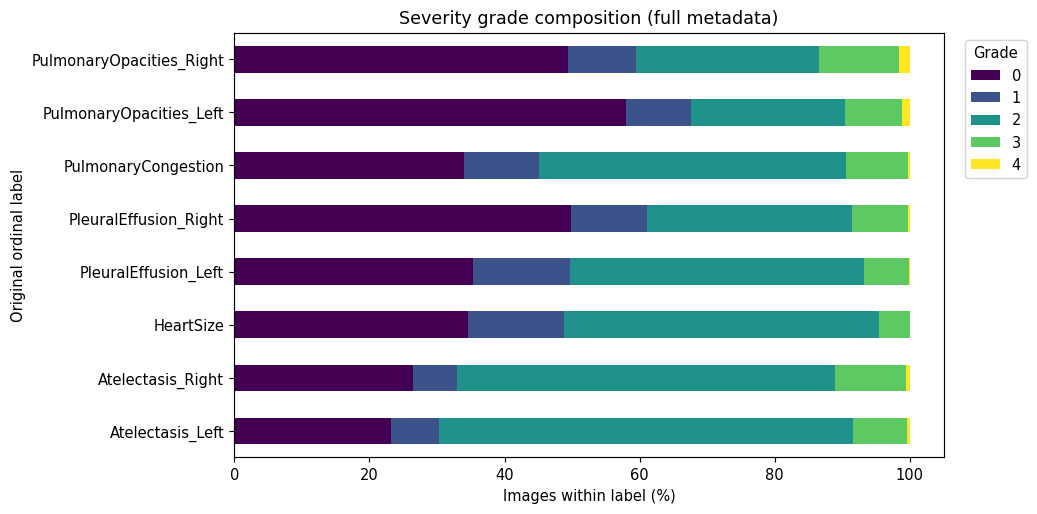

In [5]:
severity_tables = {}
for label in LABEL_COLS:
    counts = eda_df[label].value_counts().sort_index()
    severity_tables[label] = pd.DataFrame({
        "images": counts,
        "percent": (counts / len(eda_df) * 100).round(2),
    })
    print("\n", label)
    display(severity_tables[label])

severity_long = (eda_df[LABEL_COLS].melt(var_name="finding", value_name="grade")
                 .groupby(["finding", "grade"]).size().unstack(fill_value=0))
severity_percent = severity_long.div(severity_long.sum(axis=1), axis=0) * 100
ax = severity_percent.plot(kind="barh", stacked=True, figsize=(10, 5), colormap="viridis")
ax.set_xlabel("Images within label (%)")
ax.set_ylabel("Original ordinal label")
ax.set_title("Severity grade composition (full metadata)")
ax.legend(title="Grade", bbox_to_anchor=(1.02, 1), loc="upper left")
present(ax.figure, "01_severity_grades.png")

### 3.2 Exploratory 3-state grouping (not final training targets)

For EDA only, score `0 → negative`, `1 → intermediate`, `>=2 → definite positive`. For left/right pairs, either definite-positive side makes the merged finding definite-positive; otherwise any grade-1 side yields intermediate. **This is a descriptive rule, pending the team's final label policy.**

,negative,intermediate,definite_positive
Cardiomegaly,74352,30797,110232
Congestion,73076,24088,118217
PleuralEffusion,55077,27122,133182
PulmonaryOpacity,91143,23761,100477
Atelectasis,26002,11341,178038


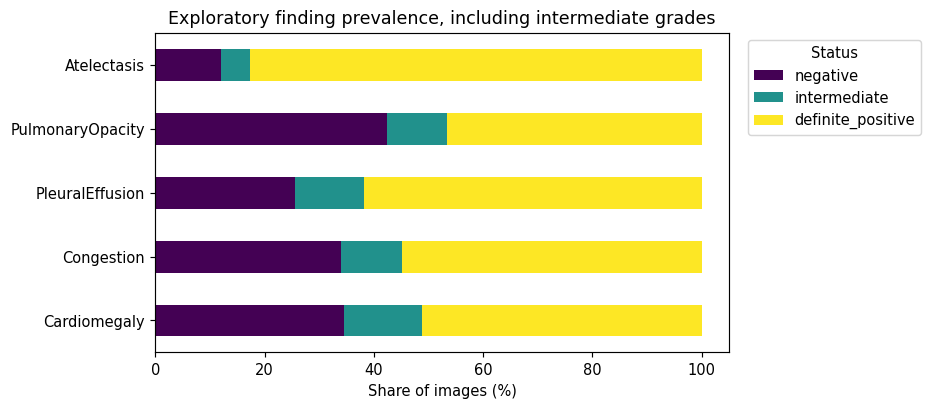

In [6]:
def single_status(values):
    return np.select(
        [values.eq(0), values.eq(1), values.ge(2)],
        ["negative", "intermediate", "definite_positive"],
        default="unexpected"
    )

def bilateral_status(left, right):
    definite = left.ge(2) | right.ge(2)
    intermediate = (~definite) & (left.eq(1) | right.eq(1))
    return np.select([definite, intermediate],
                     ["definite_positive", "intermediate"], default="negative")

eda_df["Cardiomegaly_status"] = single_status(eda_df["HeartSize"])
eda_df["Congestion_status"] = single_status(eda_df["PulmonaryCongestion"])
eda_df["PleuralEffusion_status"] = bilateral_status(
    eda_df["PleuralEffusion_Left"], eda_df["PleuralEffusion_Right"])
eda_df["PulmonaryOpacity_status"] = bilateral_status(
    eda_df["PulmonaryOpacities_Left"], eda_df["PulmonaryOpacities_Right"])
eda_df["Atelectasis_status"] = bilateral_status(
    eda_df["Atelectasis_Left"], eda_df["Atelectasis_Right"])

status_counts = pd.DataFrame({
    finding: eda_df[f"{finding}_status"].value_counts()
    for finding in FINDINGS
}).T.fillna(0).astype(int)
status_counts = status_counts.reindex(columns=["negative", "intermediate", "definite_positive"])
display(status_counts)
status_share = status_counts.div(status_counts.sum(axis=1), axis=0) * 100
ax = status_share.plot.barh(stacked=True, figsize=(9, 4), colormap="viridis")
ax.set_xlabel("Share of images (%)")
ax.set_title("Exploratory finding prevalence, including intermediate grades")
ax.legend(title="Status", bbox_to_anchor=(1.02, 1), loc="upper left")
present(ax.figure, "02_finding_status.png")

### 3.3 Left/right disagreement; multilabel burden; pair association

Merging bilateral labels is convenient but discards laterality. Co-occurrence counts can also be misleading when one finding is very prevalent; **lift** adjusts for marginal prevalence (`lift = 1` means independence).

,finding,same_grade_%,different_grade_%,left_definite_only_%,right_definite_only_%,both_definite_%,mean_abs_grade_difference
0,PleuralEffusion,49.57,50.43,22.97,11.54,27.33,0.80
1,PulmonaryOpacities,65.76,34.24,6.06,14.19,26.39,0.54
2,Atelectasis,60.05,39.95,15.65,12.91,54.09,0.66


,images,percent
0,8714,4.05
1,27364,12.70
2,43737,20.31
3,50708,23.54
4,51106,23.73
5,33752,15.67


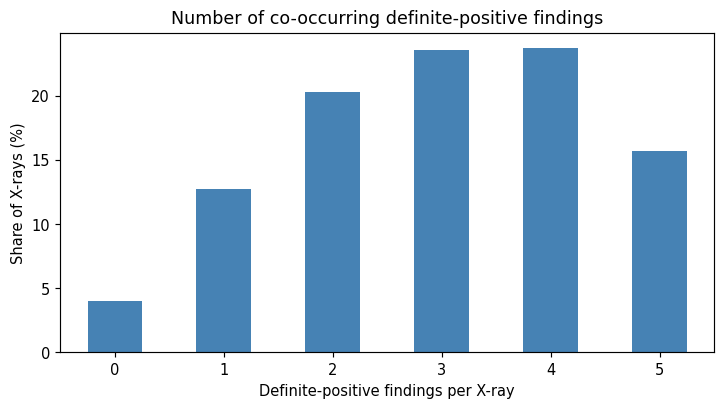

In [7]:
laterality_rows = []
for finding, (lcol, rcol) in BILATERAL.items():
    left, right = eda_df[lcol], eda_df[rcol]
    laterality_rows.append({
        "finding": finding,
        "same_grade_%": 100 * left.eq(right).mean(),
        "different_grade_%": 100 * left.ne(right).mean(),
        "left_definite_only_%": 100 * (left.ge(2) & right.lt(2)).mean(),
        "right_definite_only_%": 100 * (right.ge(2) & left.lt(2)).mean(),
        "both_definite_%": 100 * (left.ge(2) & right.ge(2)).mean(),
        "mean_abs_grade_difference": (left - right).abs().mean(),
    })
laterality_df = pd.DataFrame(laterality_rows)
display(laterality_df.round(2))

positive_df = pd.DataFrame({
    finding: eda_df[f"{finding}_status"].eq("definite_positive") for finding in FINDINGS
})
positive_cols = list(positive_df.columns)
positive_counts = positive_df.sum(axis=1)
multilabel = positive_counts.value_counts().sort_index().rename("images").to_frame()
multilabel["percent"] = 100 * multilabel["images"] / len(eda_df)
display(multilabel.round(2))

ax = multilabel["percent"].plot.bar(figsize=(7, 4), color="steelblue", rot=0)
ax.set(xlabel="Definite-positive findings per X-ray", ylabel="Share of X-rays (%)",
       title="Number of co-occurring definite-positive findings")
present(ax.figure, "03_multilabel_burden.png")

In [8]:
cooccurrence_counts = positive_df.astype(int).T @ positive_df.astype(int)
cooccurrence_pct = 100 * cooccurrence_counts / len(eda_df)
print("Co-occurrence counts:")
display(cooccurrence_counts)
print("Co-occurrence as percent of all radiographs:")
display(cooccurrence_pct.round(2))

association_rows = []
for i, a_name in enumerate(FINDINGS):
    for b_name in FINDINGS[i+1:]:
        a, b = positive_df[a_name], positive_df[b_name]
        pa, pb, pab = a.mean(), b.mean(), (a & b).mean()
        association_rows.append({
            "finding_A": a_name, "finding_B": b_name,
            "P(B|A)": pab / pa if pa else np.nan,
            "P(A|B)": pab / pb if pb else np.nan,
            "lift": pab / (pa * pb) if pa * pb else np.nan,
        })
association_df = pd.DataFrame(association_rows).sort_values("lift", ascending=False)
display(association_df.round(3))

Co-occurrence counts:


,Cardiomegaly,Congestion,PleuralEffusion,PulmonaryOpacity,Atelectasis
Cardiomegaly,110232,74960,77107,54470,95366
Congestion,74960,118217,82862,69285,102182
PleuralEffusion,77107,82862,133182,69978,123765
PulmonaryOpacity,54470,69285,69978,100477,90042
Atelectasis,95366,102182,123765,90042,178038


Co-occurrence as percent of all radiographs:


,Cardiomegaly,Congestion,PleuralEffusion,PulmonaryOpacity,Atelectasis
Cardiomegaly,51.18,34.80,35.80,25.29,44.28
Congestion,34.80,54.89,38.47,32.17,47.44
PleuralEffusion,35.80,38.47,61.84,32.49,57.46
PulmonaryOpacity,25.29,32.17,32.49,46.65,41.81
Atelectasis,44.28,47.44,57.46,41.81,82.66


,finding_A,finding_B,P(B|A),P(A|B),lift
5,Congestion,PulmonaryOpacity,0.586,0.690,1.256
0,Cardiomegaly,Congestion,0.680,0.634,1.239
4,Congestion,PleuralEffusion,0.701,0.622,1.134
1,Cardiomegaly,PleuralEffusion,0.699,0.579,1.131
7,PleuralEffusion,PulmonaryOpacity,0.525,0.696,1.126
8,PleuralEffusion,Atelectasis,0.929,0.695,1.124
9,PulmonaryOpacity,Atelectasis,0.896,0.506,1.084
2,Cardiomegaly,PulmonaryOpacity,0.494,0.542,1.059
3,Cardiomegaly,Atelectasis,0.865,0.536,1.047
6,Congestion,Atelectasis,0.864,0.574,1.046


### 3.4 Compare original and exploratory distributions across official splits

In [9]:
prevalence_by_split = (
    positive_df.assign(Split=eda_df["Split"]).groupby("Split")[FINDINGS].mean().T * 100
)
prevalence_by_split["max_gap_pp"] = prevalence_by_split.max(axis=1) - prevalence_by_split.min(axis=1)
display(prevalence_by_split.round(2))

severity_gap = []
for label in LABEL_COLS:
    table = pd.crosstab(eda_df["Split"], eda_df[label], normalize="index") * 100
    severity_gap.append({
        "label": label,
        "largest_grade_difference_pp": (table.max(axis=0) - table.min(axis=0)).max(),
    })
display(pd.DataFrame(severity_gap).sort_values("largest_grade_difference_pp", ascending=False).round(2))

Split,test,train,val,max_gap_pp
Cardiomegaly,52.26,50.81,51.32,1.46
Congestion,55.13,54.78,55.01,0.35
PleuralEffusion,61.85,61.66,62.51,0.84
PulmonaryOpacity,46.96,46.41,47.23,0.82
Atelectasis,82.54,82.65,82.85,0.32


,label,largest_grade_difference_pp
6,Atelectasis_Right,1.66
0,HeartSize,1.66
2,PleuralEffusion_Right,1.48
4,PulmonaryOpacities_Right,1.05
7,Atelectasis_Left,0.95
5,PulmonaryOpacities_Left,0.87
1,PulmonaryCongestion,0.87
3,PleuralEffusion_Left,0.72


## 4. Demographics

**Image-level** statistics weight patients by their numbers of images; **patient-level** statistics retain each patient's earliest recorded scan as their age reference. These have different denominators and should be reported separately. All ages below are derived from `Age / 365.25`.

In [10]:
image_age_summary = eda_df.groupby("Split")["Age_years"].agg(
    ["count", "mean", "median", "std", "min", "max"])
image_sex = pd.crosstab(eda_df["Split"], eda_df["Sex"], normalize="index") * 100

patient_df = (
    eda_df.sort_values(["StudyDate", "UID"])
    .drop_duplicates("PatientID", keep="first").copy()
)
patient_age_summary = patient_df.groupby("Split")["Age_years"].agg(
    ["count", "mean", "median", "std", "min", "max"])
patient_sex = pd.crosstab(patient_df["Split"], patient_df["Sex"], normalize="index") * 100

print("Image-weighted age summary:")
display(image_age_summary.round(2))
print("Patient-weighted age summary:")
display(patient_age_summary.round(2))
print("Image-level sex (% within split):")
display(image_sex.round(2))
print("Patient-level sex (% within split):")
display(patient_sex.round(2))

Image-weighted age summary:


,count,mean,median,std,min,max
Split,,,,,,
test,42928,65.53,68.15,14.88,0.0,102.35
train,137593,65.71,68.17,14.58,0.0,110.65
val,34860,66.01,68.56,14.23,0.0,98.97


Patient-weighted age summary:


,count,mean,median,std,min,max
Split,,,,,,
test,9545,66.41,69.04,15.68,0.0,102.35
train,30543,66.34,69.08,15.76,0.0,110.63
val,7636,66.39,69.27,15.77,0.0,98.97


Image-level sex (% within split):


Sex,F,M
Split,,
test,32.39,67.61
train,33.93,66.07
val,32.04,67.96


Patient-level sex (% within split):


Sex,F,M
Split,,
test,36.44,63.56
train,36.48,63.52
val,36.66,63.34


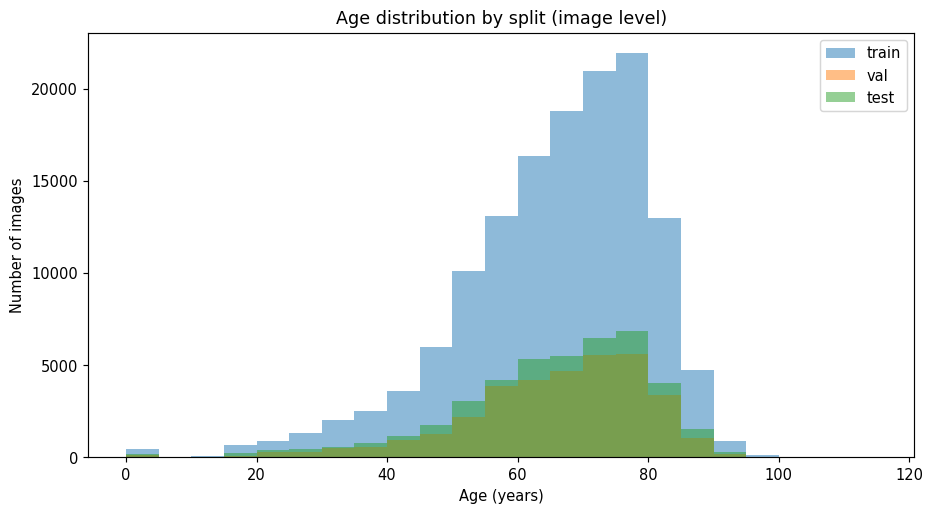

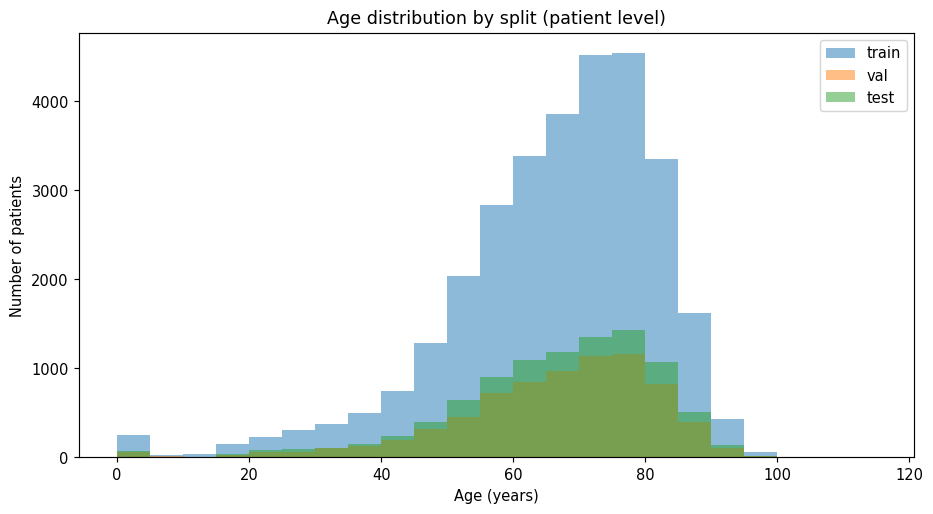

In [11]:
# Shared bin edges ensure a meaningful histogram comparison.
age_bins = np.arange(0, max(115, int(np.ceil(eda_df["Age_years"].max())) + 5), 5)
for frame, ylabel, title, filename in [
    (eda_df, "Number of images", "Age distribution by split (image level)", "04_age_by_image.png"),
    (patient_df, "Number of patients", "Age distribution by split (patient level)", "05_age_by_patient.png"),
]:
    fig, ax = plt.subplots(figsize=(9, 5))
    for split_name in SPLITS:
        ax.hist(frame.loc[frame["Split"] == split_name, "Age_years"],
                bins=age_bins, alpha=0.5, label=split_name)
    ax.set(xlabel="Age (years)", ylabel=ylabel, title=title)
    ax.legend()
    present(fig, filename)

## 5. Temporal and longitudinal structure

`StudyDate` is **privacy-shifted** and cannot be treated as an exact calendar acquisition date. Trends across broad periods can still be useful, but 2009/2024 boundary observations and the estimated 2016 detector transition need caution. The official splits are not chronological holdouts.

In [12]:
print("Missing or unparseable StudyDate:", eda_df["StudyDate"].isna().sum())
images_by_year = eda_df["StudyYear"].value_counts().sort_index()
year_split_counts = pd.crosstab(eda_df["StudyYear"], eda_df["Split"]).reindex(columns=SPLITS)
year_split_percent = pd.crosstab(
    eda_df["StudyYear"], eda_df["Split"], normalize="index"
).reindex(columns=SPLITS) * 100

display(images_by_year.to_frame("images"))
display(year_split_counts)
display(year_split_percent.round(2))

Missing or unparseable StudyDate: 0


,images
StudyYear,
2009,1336
2010,17423
2011,19164
2012,19478
2013,17940
2014,17834
2015,16227
2016,14872
2017,13566


Split,train,val,test
StudyYear,,,
2009,844,268,224
2010,10923,2963,3537
2011,12169,2913,4082
2012,12221,3231,4026
2013,11736,2729,3475
2014,11429,2918,3487
2015,10342,2731,3154
2016,9373,2382,3117
2017,8553,2084,2929


Split,train,val,test
StudyYear,,,
2009,63.17,20.06,16.77
2010,62.69,17.01,20.30
2011,63.50,15.20,21.30
2012,62.74,16.59,20.67
2013,65.42,15.21,19.37
2014,64.09,16.36,19.55
2015,63.73,16.83,19.44
2016,63.02,16.02,20.96
2017,63.05,15.36,21.59


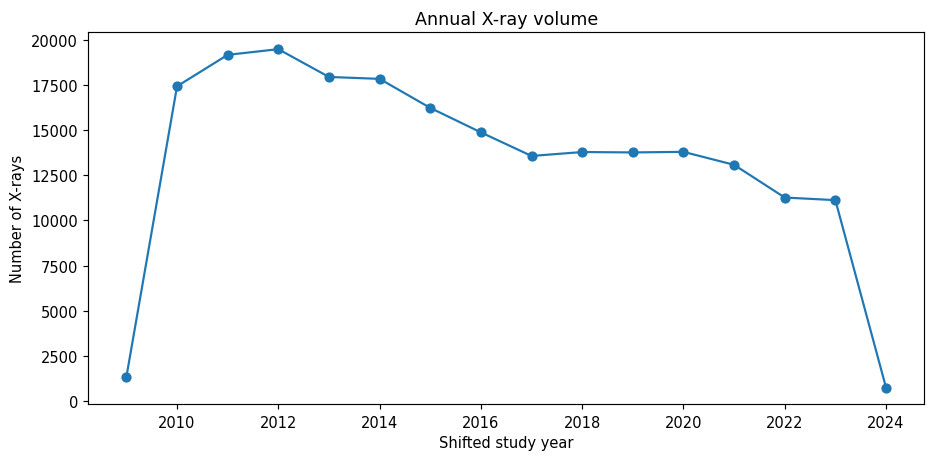

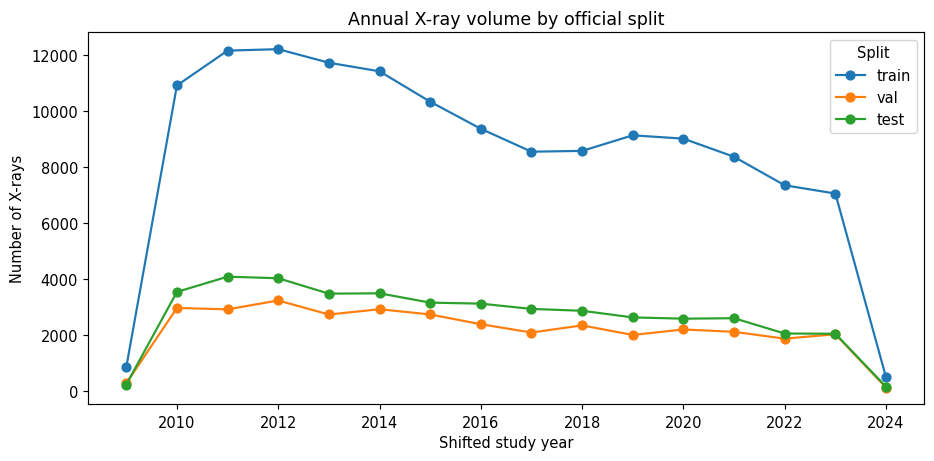

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(images_by_year.index, images_by_year.values, marker="o")
ax.set(xlabel="Shifted study year", ylabel="Number of X-rays", title="Annual X-ray volume")
present(fig, "06_images_by_year.png")

ax = year_split_counts.plot(kind="line", marker="o", figsize=(9, 4.5))
ax.set(xlabel="Shifted study year", ylabel="Number of X-rays",
       title="Annual X-ray volume by official split")
present(ax.figure, "07_images_by_year_split.png")

### 5.1 Follow-up time among patients with repeat images

`span_days` is the time from a patient's **first to last recorded X-ray**, **not** ICU length of stay, admission duration, or time between successive scans. Same-day repeat scans can have a zero-day span.

In [14]:
patient_timeline = eda_df.groupby("PatientID").agg(
    first_scan=("StudyDate", "min"), last_scan=("StudyDate", "max"),
    n_scans=("UID", "count"),
)
patient_timeline["span_days"] = (patient_timeline["last_scan"] - patient_timeline["first_scan"]).dt.days
repeated_patients = patient_timeline.loc[patient_timeline["n_scans"] > 1]
print("Repeat-imaged patients:", len(repeated_patients))
display(repeated_patients["span_days"].describe().round(2))

span = repeated_patients["span_days"]
span_buckets = pd.Series({
    "Same day": span.eq(0).sum(),
    "1–7 days": span.between(1, 7).sum(),
    "8–30 days": span.between(8, 30).sum(),
    "31–365 days": span.between(31, 365).sum(),
    ">365 days": span.gt(365).sum(),
}, name="patients").to_frame()
span_buckets["percent"] = 100 * span_buckets["patients"] / len(repeated_patients)
display(span_buckets.round(2))
assert span_buckets["patients"].sum() == len(repeated_patients)

Repeat-imaged patients: 31131


,span_days
count,31131.00
mean,275.18
std,562.02
min,0.00
25%,81.00
50%,138.00
75%,182.00
max,5199.00


,patients,percent
Same day,38,0.12
1–7 days,598,1.92
8–30 days,1963,6.31
31–365 days,25219,81.01
>365 days,3313,10.64


## 6. Reproducible image sample

Each split contributes 300 images, sampled with `random_state=0`. The **manifest is authoritative**: if it already exists, it is reused rather than replaced. A new teammate can recreate the same sample from the raw metadata and seed or share the small manifest file.

The images are streamed/downloaded **only if** `DOWNLOAD_MISSING_IMAGES=True`; otherwise missing PNGs are reported and image-only analyses are skipped. Do not delete local images or attempt a full-dataset download for this EDA.

In [15]:
if MANIFEST_PATH.exists():
    manifest = pd.read_csv(MANIFEST_PATH, dtype={"UID": str, "PatientID": str})
    print("Using existing sample manifest:", MANIFEST_PATH)
else:
    sampled = [eda_df.loc[eda_df["Split"] == split].sample(
        n=SAMPLE_PER_SPLIT, random_state=RANDOM_SEED)[["UID", "Split", "PatientID"]]
        for split in SPLITS]
    manifest = pd.concat(sampled, ignore_index=True)
    manifest.to_csv(MANIFEST_PATH, index=False)
    print("Created deterministic sample manifest:", MANIFEST_PATH)

assert manifest["UID"].is_unique, "Manifest includes duplicate image UIDs"
assert set(manifest["Split"]).issubset(set(SPLITS))
check_manifest = manifest.merge(
    eda_df[["UID", "Split", "PatientID"]], on="UID", how="left",
    suffixes=("_manifest", "_metadata"), validate="one_to_one", indicator=True)
assert check_manifest["_merge"].eq("both").all(), "Manifest UID missing from metadata"
assert check_manifest["Split_manifest"].eq(check_manifest["Split_metadata"]).all(), "Split mismatch"
assert check_manifest["PatientID_manifest"].eq(check_manifest["PatientID_metadata"]).all(), "Patient mismatch"

sample_df = manifest.copy()
sample_df["image_path"] = sample_df["UID"].map(lambda uid: SAMPLE_DIR / f"{uid}.png")
print("Manifest rows:", len(sample_df))
display(sample_df["Split"].value_counts().reindex(SPLITS))

Using existing sample manifest: /content/drive/MyDrive/TAIX-Ray/eda_image_sample_manifest.csv
Manifest rows: 900


,count
Split,
train,300
val,300
test,300


In [16]:
# Optional download: do not trigger it unless explicitly enabled in configuration.
missing_rows = sample_df.loc[~sample_df["image_path"].map(Path.exists)]
print(f"Missing PNGs: {len(missing_rows)} / {len(sample_df)}")

if DOWNLOAD_MISSING_IMAGES and not missing_rows.empty:
    # Streaming traverses remote rows. On first run this can take considerable time.
    ds = open_taix_stream()
    for split in SPLITS:
        wanted = set(missing_rows.loc[missing_rows["Split"] == split, "UID"])
        if not wanted:
            continue
        print(f"Fetching {len(wanted)} missing {split} PNGs...")
        for example in tqdm(ds[split].select_columns(["UID", "Image"]),
                            total=EXPECTED_SPLIT_SIZES[split], desc=f"Stream {split}"):
            uid = str(example["UID"])
            if uid not in wanted:
                continue
            output_path = SAMPLE_DIR / f"{uid}.png"
            # Save in the same format as the original notebook, without converting to RGB.
            example["Image"].save(output_path, format="PNG")
            wanted.remove(uid)
            if not wanted:
                break
        if wanted:
            raise RuntimeError(f"Not found in remote {split} split: {len(wanted)} requested UIDs")

sample_df["file_exists"] = sample_df["image_path"].map(Path.exists)
IMAGES_AVAILABLE = bool(sample_df["file_exists"].all())
print("Sample ready:", IMAGES_AVAILABLE, "| Files:", int(sample_df["file_exists"].sum()))
if not IMAGES_AVAILABLE:
    print("Image-only sections will be skipped. Set DOWNLOAD_MISSING_IMAGES=True, or copy the files into:", SAMPLE_DIR)

Missing PNGs: 0 / 900
Sample ready: True | Files: 900


## 7. Image geometry and intensity

This section runs **only when all sample PNGs are available**. Image statistics are stored in two CSVs and reused on later runs. They measure **stored pixel values**, not the final model input tensor. `I;16` is a 16-bit grayscale *container mode*, not evidence of uniform effective intensity bit depth.

In [17]:
def cache_matches(frame):
    return (len(frame) == len(sample_df)
            and "UID" in frame.columns
            and set(frame["UID"].astype(str)) == set(sample_df["UID"].astype(str))
            and frame["UID"].is_unique)

image_info_df = pixel_info_df = None
if GEOMETRY_CACHE.exists() and PIXEL_CACHE.exists() and not REBUILD_IMAGE_STATS:
    candidate_image = pd.read_csv(GEOMETRY_CACHE, dtype={"UID": str, "PatientID": str})
    candidate_pixel = pd.read_csv(PIXEL_CACHE, dtype={"UID": str})
    if cache_matches(candidate_image) and cache_matches(candidate_pixel):
        image_info_df, pixel_info_df = candidate_image, candidate_pixel
        print("Using cached 900-image statistics.")
    else:
        print("Cached image statistics do not match manifest; will recompute if files exist.")

if (image_info_df is None or pixel_info_df is None) and IMAGES_AVAILABLE:
    geo_rows, intensity_rows = [], []
    for row in tqdm(sample_df.itertuples(index=False), total=len(sample_df), desc="Read PNGs"):
        path = row.image_path
        with Image.open(path) as img:
            width, height = img.size
            fmt, mode = img.format, img.mode
            pixels = np.asarray(img)
        geo_rows.append({
            "UID": row.UID, "Split": row.Split, "PatientID": row.PatientID,
            "width": width, "height": height, "aspect_ratio": width / height,
            "mode": mode, "format": fmt, "file_size_kb": path.stat().st_size / 1024,
        })
        intensity_rows.append({
            "UID": row.UID, "Split": row.Split,
            "min_intensity": int(pixels.min()), "max_intensity": int(pixels.max()),
            "mean_intensity": float(pixels.mean()), "std_intensity": float(pixels.std()),
            "p01": float(np.percentile(pixels, 1)), "p99": float(np.percentile(pixels, 99)),
        })
    image_info_df = pd.DataFrame(geo_rows)
    pixel_info_df = pd.DataFrame(intensity_rows)
    image_info_df.to_csv(GEOMETRY_CACHE, index=False)
    pixel_info_df.to_csv(PIXEL_CACHE, index=False)
    print("Saved:", GEOMETRY_CACHE, "and", PIXEL_CACHE)

IMAGE_STATS_AVAILABLE = image_info_df is not None and pixel_info_df is not None
print("Image statistics ready:", IMAGE_STATS_AVAILABLE)

Using cached 900-image statistics.
Image statistics ready: True


### 7.1 Geometry, storage, and split comparisons

From the 2026 sample: most images are non-square with the longest dimension capped at 512 pixels. Input resolution (e.g. a proposed **448 × 448**) and **resizing policy** (warp vs aspect-preserving padding vs crop) are separate Data Preparation decisions.

In [18]:
if IMAGE_STATS_AVAILABLE:
    display(image_info_df[["width", "height", "aspect_ratio", "file_size_kb"]].describe().round(2))
    print("PIL modes:"); display(image_info_df["mode"].value_counts())
    print("File formats:"); display(image_info_df["format"].value_counts())
    display(image_info_df.groupby(["width", "height"]).size().sort_values(ascending=False).head(15))
    display(image_info_df.groupby("Split")[["width", "height", "aspect_ratio", "file_size_kb"]]
            .agg(["mean", "median", "min", "max"]).round(2))
else:
    print("Skipped geometry tables: download the sample or supply matching cached CSVs.")

,width,height,aspect_ratio,file_size_kb
count,900.00,900.00,900.00,900.00
mean,511.66,425.32,1.21,262.63
std,5.42,18.26,0.05,58.20
min,415.00,341.00,0.81,85.31
25%,512.00,419.00,1.22,219.28
50%,512.00,421.00,1.22,233.83
75%,512.00,421.00,1.22,319.87
max,512.00,512.00,1.50,395.89


PIL modes:


,count
mode,
I;16,900


File formats:


,count
format,
PNG,900


width  height
512    421       499
       419       175
       435        11
       451         7
       443         6
       434         5
       450         5
       438         5
       436         5
       444         5
       431         4
       432         4
       445         4
       446         4
       442         4
dtype: int64

width                   height                  aspect_ratio         \
         mean median  min  max    mean median  min  max         mean median   
Split                                                                         
test   511.70  512.0  421  512  424.34  421.0  341  512         1.21   1.22   
train  511.60  512.0  415  512  426.65  421.0  382  512         1.20   1.22   
val    511.68  512.0  421  512  424.96  421.0  341  512         1.21   1.22   

                  file_size_kb                          
        min   max         mean  median     min     max  
Split                                                   
test   0.82  1.50       258.94  232.91  137.64  388.08  
train  0.81  1.34       265.22  236.93  106.69  388.74  
val    0.82  1.50       263.74  232.40   85.31  395.89

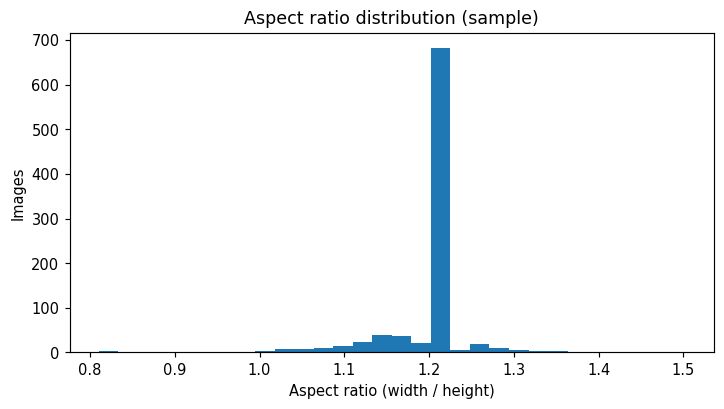

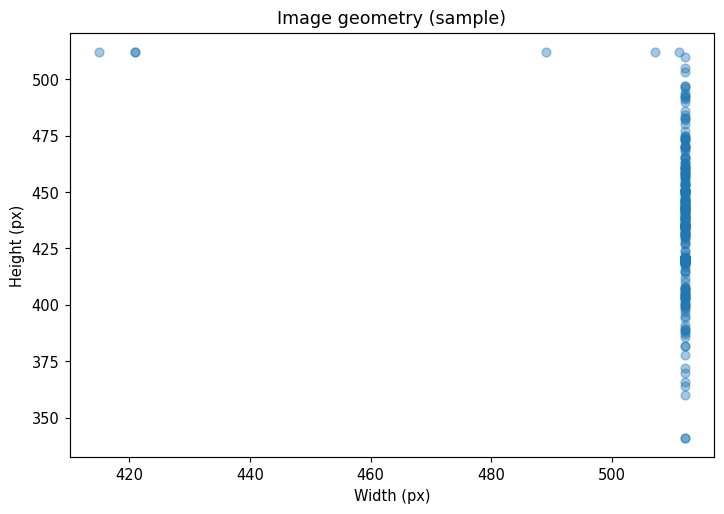

In [19]:
if IMAGE_STATS_AVAILABLE:
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.hist(image_info_df["aspect_ratio"], bins=30)
    ax.set(xlabel="Aspect ratio (width / height)", ylabel="Images",
           title="Aspect ratio distribution (sample)")
    present(fig, "08_aspect_ratios.png")

    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(image_info_df["width"], image_info_df["height"], alpha=0.4)
    ax.set(xlabel="Width (px)", ylabel="Height (px)", title="Image geometry (sample)")
    present(fig, "09_width_vs_height.png")

### 7.2 Raw pixel intensities

The sample has two prominent *observed maximum* groups, `<=4095` versus `>4095`. This does not prove two detector models. In the source paper, the authors describe retaining intensity differences rather than applying global intensity normalization. **Do not divide every image blindly by 4095 or 65535 and assume comparable intensity scaling.**

In [20]:
if IMAGE_STATS_AVAILABLE:
    display(pixel_info_df[["min_intensity", "max_intensity", "mean_intensity",
                           "std_intensity", "p01", "p99"]].describe().round(2))
    display(pixel_info_df["max_intensity"].value_counts().head(10))
    pixel_info_df["intensity_group"] = np.where(
        pixel_info_df["max_intensity"].le(4095), "Up to 4095", "Above 4095")
    display(pixel_info_df["intensity_group"].value_counts())
    display((pd.crosstab(pixel_info_df["Split"], pixel_info_df["intensity_group"],
                         normalize="index") * 100).round(2))
    display(pixel_info_df.groupby("intensity_group")[["mean_intensity", "std_intensity", "p01", "p99"]]
            .agg(["mean", "median", "min", "max"]).round(2))

,min_intensity,max_intensity,mean_intensity,std_intensity,p01,p99
count,900.00,900.00,900.00,900.00,900.00,900.00
mean,421.54,31002.71,12343.95,3837.13,1821.80,18925.98
std,2395.83,30361.43,12586.27,3429.01,4909.25,17812.64
min,0.00,3353.00,733.97,320.96,0.00,1970.65
25%,0.00,4095.00,1894.82,905.81,0.00,3539.00
50%,0.00,4095.00,2232.15,1093.94,16.00,3712.74
75%,16.00,65280.00,23751.79,7018.20,422.50,37427.30
max,28138.00,65280.00,49797.84,12812.83,31410.00,56917.00


,count
max_intensity,
65280,393
4095,319
4094,10
4093,9
4090,3
4052,3
3833,3
3892,2
4084,2


,count
intensity_group,
Up to 4095,502
Above 4095,398


intensity_group,Above 4095,Up to 4095
Split,,
test,41.67,58.33
train,45.00,55.00
val,46.00,54.00


mean_intensity                              std_intensity  \
                          mean    median      min       max          mean   
intensity_group                                                             
Above 4095            25499.83  25585.82  9679.61  49797.84       7497.15   
Up to 4095             1913.60   1933.73   733.97   2669.66        935.36   

                                                 p01                       \
                  median      min       max     mean median  min      max   
intensity_group                                                             
Above 4095       7281.46  4134.24  12812.83  4021.53   64.0  0.0  31410.0   
Up to 4095        922.78   320.96   1378.43    77.80    0.0  0.0    941.0   

                      p99                              
                     mean   median       min      max  
intensity_group                                        
Above 4095       38299.83  38537.0  21687.09  56917.0  
Up to 4095        3565.83   3554.0   1970.65   4088.0

Example pixel shape / dtype / range: (421, 512) uint16 (0, 4095)


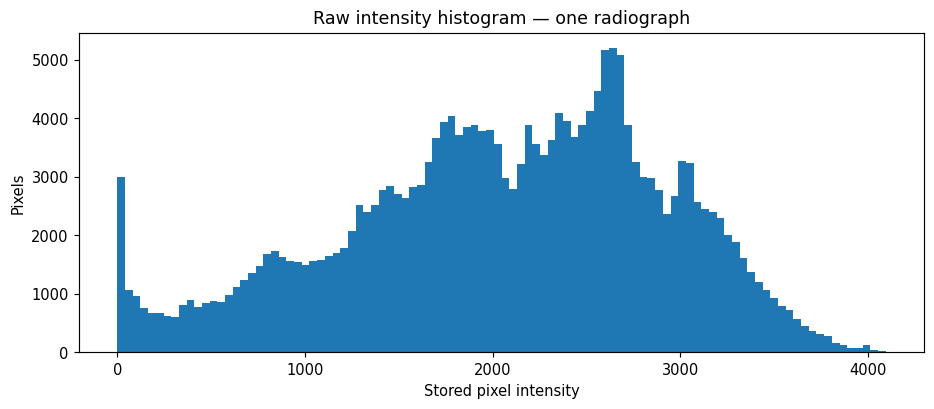

High-range image unique values: 36043
Fraction of pixels divisible by 256: 0.00406


In [21]:
if IMAGES_AVAILABLE:
    row = sample_df.iloc[0]
    with Image.open(row["image_path"]) as img:
        pixels = np.array(img)
        print("Example pixel shape / dtype / range:", pixels.shape, pixels.dtype,
              (int(pixels.min()), int(pixels.max())))
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(pixels.ravel(), bins=100)
    ax.set(xlabel="Stored pixel intensity", ylabel="Pixels",
           title="Raw intensity histogram — one radiograph")
    present(fig, "10_one_image_histogram.png")

    # A single high-range example tests the naive hypothesis that pixels = 8-bit × 256.
    high_examples = pixel_info_df.loc[pixel_info_df["max_intensity"].eq(65280), "UID"]
    if not high_examples.empty:
        high_uid = high_examples.iloc[0]
        with Image.open(SAMPLE_DIR / f"{high_uid}.png") as img:
            high_pixels = np.asarray(img)
        print("High-range image unique values:", len(np.unique(high_pixels)))
        print("Fraction of pixels divisible by 256:", round(float((high_pixels % 256 == 0).mean()), 5))

### 7.3 Six-image exploratory visual review

Three reproducibly selected images from each intensity group are displayed after **per-image p01–p99 scaling for viewing only**. This is **not** the team's agreed preprocessing transform. Look for framing, markers, equipment, visible image artifacts; **do not infer clinical labels or detector manufacturer from six images**.

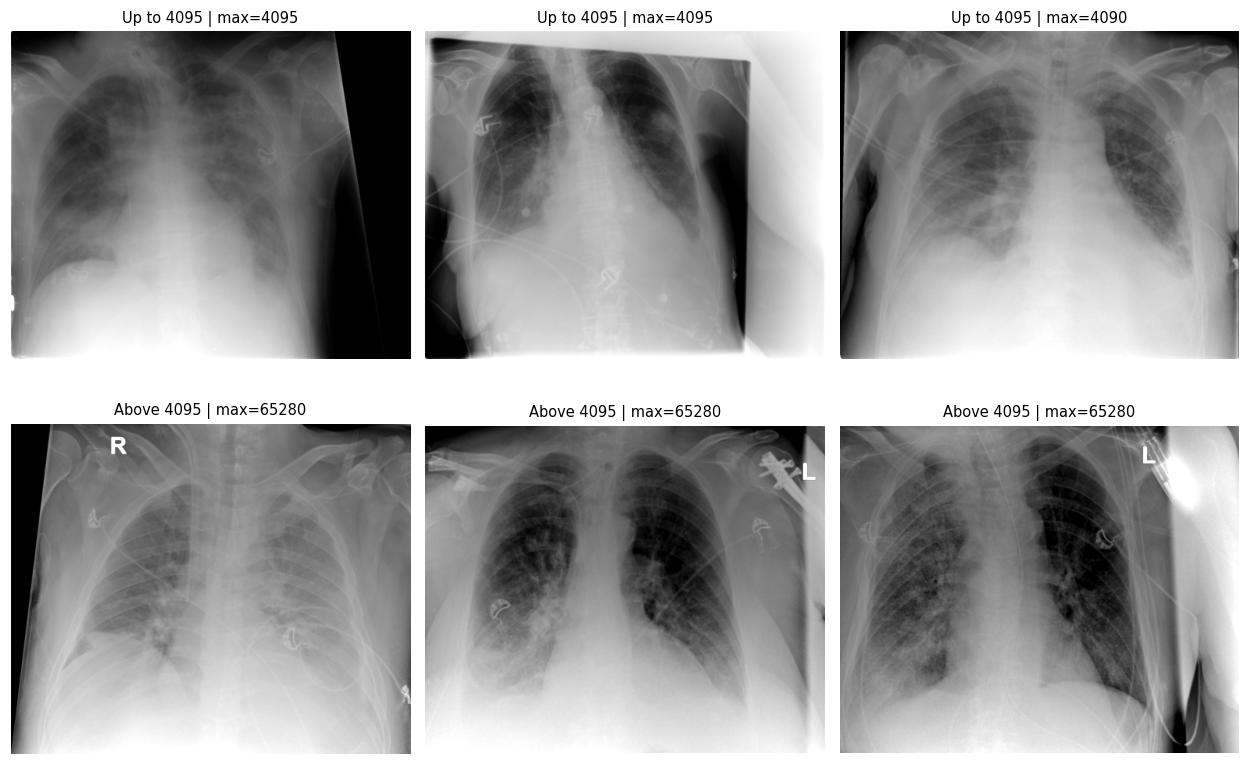

In [22]:
def normalize_for_display(pixels):
    arr = np.asarray(pixels, dtype=np.float32)
    p01, p99 = np.percentile(arr, [1, 99])
    if p99 <= p01:
        return np.zeros_like(arr)
    return np.clip((arr - p01) / (p99 - p01), 0, 1)

if IMAGES_AVAILABLE and IMAGE_STATS_AVAILABLE:
    # Use a fixed seed per group; results are reproducible with the same manifest.
    qc_parts = [pixel_info_df.loc[pixel_info_df["intensity_group"].eq(group)]
                .sample(n=3, random_state=42)
                for group in ["Up to 4095", "Above 4095"]]
    qc_samples = pd.concat(qc_parts, ignore_index=True)
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))
    for ax, row in zip(axes.flat, qc_samples.itertuples(index=False)):
        with Image.open(SAMPLE_DIR / f"{row.UID}.png") as img:
            px = np.asarray(img)
        ax.imshow(normalize_for_display(px), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{row.intensity_group} | max={row.max_intensity}", fontsize=10)
        ax.axis("off")
    present(fig, "11_six_image_visual_qc.png")

## 8. Acquisition-era intensity pattern

The **high-intensity fraction by shifted year** was a major finding: the sample's dominant intensity range changes sharply around 2015–2017, consistent with the paper's description of the move toward digital flat-panel acquisition around 2016. This is an **association, not a proven causal assignment of images to detector types**. Counts per year matter: boundary years have very small samples.

,sample_images,Above 4095,Up to 4095
StudyYear,,,
2009,4,0.00,100.00
2010,62,0.00,100.00
2011,81,0.00,100.00
2012,95,0.00,100.00
2013,82,0.00,100.00
2014,95,0.00,100.00
2015,72,23.61,76.39
2016,72,76.39,23.61
2017,41,97.56,2.44


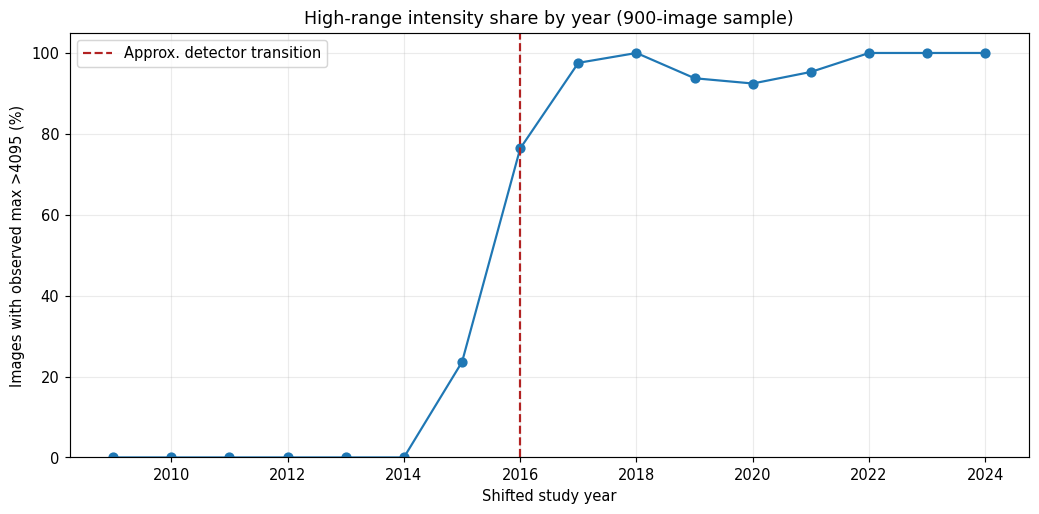

In [23]:
if IMAGE_STATS_AVAILABLE:
    pixel_year_df = pixel_info_df.merge(
        eda_df[["UID", "StudyYear"]], on="UID", how="left", validate="one_to_one")
    n_by_year = pixel_year_df.groupby("StudyYear").size().rename("sample_images")
    pct_by_year = (pd.crosstab(pixel_year_df["StudyYear"],
                              pixel_year_df["intensity_group"], normalize="index") * 100)
    intensity_year_table = n_by_year.to_frame().join(pct_by_year)
    display(intensity_year_table.round(2))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(intensity_year_table.index, intensity_year_table["Above 4095"], marker="o")
    ax.axvline(2016, color="firebrick", linestyle="--", label="Approx. detector transition")
    ax.set(xlabel="Shifted study year", ylabel="Images with observed max >4095 (%)",
           title="High-range intensity share by year (900-image sample)")
    ax.set_ylim(0, 105)
    ax.legend()
    ax.grid(alpha=0.25)
    present(fig, "12_high_intensity_by_year.png")

## 9. Metadata and image integrity audit

These checks establish **schema and decoding validity**, not that each annotation is clinically correct. Grade 1 explicitly encodes uncertainty. Missingness is tested on the raw fields (plus date parse result), not only derived columns.

In [24]:
missing_summary = pd.DataFrame({
    "missing_count": eda_df[RAW_COLS].isna().sum(),
    "missing_percent": eda_df[RAW_COLS].isna().mean() * 100,
})
display(missing_summary.round(2))

invalid_grades = {}
for col in LABEL_COLS:
    allowed = {0, 1, 2, 3} if col == "HeartSize" else {0, 1, 2, 3, 4}
    invalid_grades[col] = int((eda_df[col].notna() & ~eda_df[col].isin(allowed)).sum())

audit = pd.Series({
    "Duplicate UIDs": int(eda_df["UID"].duplicated().sum()),
    "Unique patients": int(eda_df["PatientID"].nunique()),
    "Invalid ordinal grades": sum(invalid_grades.values()),
    "Negative age": int((pd.to_numeric(eda_df["Age"], errors="coerce") < 0).sum()),
    "Age >120 years": int((eda_df["Age_years"] > 120).sum()),
    "Unexpected sex code": int((eda_df["Sex"].notna() & ~eda_df["Sex"].isin(["M", "F"])).sum()),
    "Unexpected split code": int((eda_df["Split"].notna() & ~eda_df["Split"].isin(SPLITS)).sum()),
    "Unparseable/missing dates": int(eda_df["StudyDate"].isna().sum()),
    "Patients in >1 split": int((eda_df.groupby("PatientID")["Split"].nunique() > 1).sum()),
}, name="value")
print("Invalid grade count by label:")
display(pd.Series(invalid_grades, name="invalid_count").to_frame())
print("Metadata integrity:")
display(audit.to_frame())

,missing_count,missing_percent
UID,0,0.0
Fold,0,0.0
Split,0,0.0
PatientID,0,0.0
PhysicianID,0,0.0
StudyDate,0,0.0
Age,0,0.0
Sex,0,0.0
HeartSize,0,0.0
PulmonaryCongestion,0,0.0


Invalid grade count by label:


,invalid_count
HeartSize,0
PulmonaryCongestion,0
PleuralEffusion_Right,0
PleuralEffusion_Left,0
PulmonaryOpacities_Right,0
PulmonaryOpacities_Left,0
Atelectasis_Right,0
Atelectasis_Left,0


Metadata integrity:


,value
Duplicate UIDs,0
Unique patients,47724
Invalid ordinal grades,0
Negative age,0
Age >120 years,0
Unexpected sex code,0
Unexpected split code,0
Unparseable/missing dates,0
Patients in >1 split,0


In [25]:
# Optional end-to-end file check. Even with cached image stats, this independently verifies
# container structure and fully decodes all 900 downloaded PNGs.
image_errors = []
if VERIFY_ALL_SAMPLE_PNGS and IMAGES_AVAILABLE:
    for row in tqdm(sample_df.itertuples(index=False), total=len(sample_df), desc="Verify and decode PNGs"):
        try:
            with Image.open(row.image_path) as img:
                img.verify()
            with Image.open(row.image_path) as img:
                img.load()
        except (OSError, ValueError, UnidentifiedImageError) as exc:
            image_errors.append({"UID": row.UID, "error": str(exc)})
    print("Sample PNG verification/decode errors:", len(image_errors))
elif VERIFY_ALL_SAMPLE_PNGS:
    print("Cannot verify: the 900 PNG sample is incomplete.")
else:
    print("Optional PNG verification skipped (set VERIFY_ALL_SAMPLE_PNGS=True).")

Optional PNG verification skipped (set VERIFY_ALL_SAMPLE_PNGS=True).


## 10. Conclusions and handoff

**Validated on the complete metadata:** patient-disjoint official splits; original ordinal-grade values and demographic/temporal distributions; no missing fields or invalid values under tested constraints. The cohort has repeated scans per patient, and the splits mix years rather than reserving a later acquisition period as an out-of-time test.

**Observed in the 900-image sample:** non-square images with preserved aspect ratios; uniform 16-bit grayscale PNG storage but heterogeneous pixel ranges; striking 2015–2017 association between acquisition year and high-range image intensities. Six-image visual review showed plausible anatomical visibility after *display-only* normalization. In the original EDA run, **900/900 sample images passed verification and full decoding**; rerun the optional integrity cell to confirm in another environment.

**Carry into Data Preparation:**
1. Decide the actual outputs and grade-1 / borderline / laterality policy (the 5-finding EDA simplification is **not** a frozen ground truth transform).
2. Confirm the planned **448 × 448** input size with the exact pretrained EVA-X checkpoint and DenseNet pipeline; decide direct resizing vs aspect-preserving padding/cropping, interpolation, and channel mapping.
3. Choose and document a normalization strategy that handles acquisition-era intensity scales; fit any population statistics **on train only**.
4. Compare models under a documented downstream protocol, retain the official untouched patient-disjoint test split, and consider evaluation by acquisition era/intensity group (alongside age/sex).
5. Do not interpret completeness and valid grade codes as proof of clinical annotation correctness.

**Outputs:** `taix_metadata_eda.parquet` (raw cache), `eda_image_sample_manifest.csv`, 900 locally cached PNGs (optional), `eda_image_characteristics.csv`, `eda_pixel_characteristics.csv`, and generated charts under `eda_outputs/figures/`. All intermediate data stays out of Git except the notebook and optionally a manifest if the team elects to track it.

**References:** [Dataset page](https://huggingface.co/datasets/TLAIM/TAIX-Ray) · [Truhn et al. (2026)](https://www.nature.com/articles/s41597-026-07271-7) · [Hugging Face streaming guide](https://huggingface.co/docs/datasets/stream)